# SQL Database Project: Brazilian E-Commerce (Olist)

## 1. Prepare the environment

Configure workspace paths, import standard scientific libraries, and download the Brazilian E-Commerce dataset directly using `kagglehub`.

In [2]:
from pathlib import Path
from zipfile import ZipFile
import json
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import kagglehub
from IPython.display import display

# Download latest version
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
print("Path to dataset files:", path)

# Instead of looking for a zip archive, we will reference the extracted files directory
DATA_DIR = Path(path)
if not DATA_DIR.exists() or not list(DATA_DIR.glob("*.csv")):
    raise FileNotFoundError(f"No CSV files found in the dataset directory: {DATA_DIR}")

# Set a flag or dummy ZIP_PATH to prevent breaking downstream logic if it expects ZIP_PATH,
# but we will adapt downstream cells to read directly from the CSV files.
ZIP_PATH = None

OUTPUT_DIR = Path.cwd()
DB_PATH = OUTPUT_DIR / 'olist_ecommerce_project.sqlite'
JSONL_PATH = OUTPUT_DIR / 'olist_orders_documents_sample.jsonl'
RANDOM_SEED = 42

print('Source directory:', DATA_DIR)
print('SQLite output:', DB_PATH)
print('Python SQLite version:', sqlite3.sqlite_version)

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Path to dataset files: /kaggle/input/brazilian-ecommerce
Source directory: /kaggle/input/brazilian-ecommerce
SQLite output: /content/olist_ecommerce_project.sqlite
Python SQLite version: 3.45.1


## 2. Inspect the raw dataset

Scan the downloaded directory to discover the raw CSV files, verify their sizes, and ensure all nine standard files are present.

In [6]:
csv_paths = sorted(list(DATA_DIR.glob('*.csv')))
csv_names = [p.name for p in csv_paths]
manifest = pd.DataFrame({
    'CSV file': csv_names,
    'Size (MB)': [round(p.stat().st_size / 1e6, 2) for p in csv_paths]
})
display(manifest)
assert len(csv_names) == 9, 'Expected the nine standard Olist CSV files.'

,CSV file,Size (MB)
0,olist_customers_dataset.csv,9.03
1,olist_geolocation_dataset.csv,61.27
2,olist_order_items_dataset.csv,15.44
3,olist_order_payments_dataset.csv,5.78
4,olist_order_reviews_dataset.csv,14.45
5,olist_orders_dataset.csv,17.65
6,olist_products_dataset.csv,2.38
7,olist_sellers_dataset.csv,0.17
8,product_category_name_translation.csv,0.00


## 3. Load, clean and type the source data

This section loads the nine raw CSV tables into pandas, enforces strict data types, and prepares the datasets for the relational schema based on the following structural decisions:
* **Translation Mapping**: Resolves untranslated categories to prevent lost records during SQL joins.
* **Geolocation Aggregation**: Compresses 1M+ redundant geolocation coordinates to unique zip-code centroids to optimize storage and indexing efficiency.
* **Schema Alignment**: Renames fields to maintain consistent nomenclature across primary/foreign keys and forces numeric conversions on metric columns.

In [7]:
FILES = {
    'customers': 'olist_customers_dataset.csv',
    'orders': 'olist_orders_dataset.csv',
    'items': 'olist_order_items_dataset.csv',
    'payments': 'olist_order_payments_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'translations': 'product_category_name_translation.csv',
    'geolocation': 'olist_geolocation_dataset.csv',
}
ZIP_COLUMNS = {
    'customers': {'customer_zip_code_prefix': str},
    'sellers': {'seller_zip_code_prefix': str},
    'geolocation': {'geolocation_zip_code_prefix': str},
}

source = {}
for short_name, file_name in FILES.items():
    file_path = DATA_DIR / file_name
    source[short_name] = pd.read_csv(
        file_path, dtype=ZIP_COLUMNS.get(short_name), low_memory=False
    )

source_overview = pd.DataFrame([
    {'source': name, 'rows': len(df), 'columns': len(df.columns),
     'missing_cells': int(df.isna().sum().sum())}
    for name, df in source.items()
])
display(source_overview)

,source,rows,columns,missing_cells
0,customers,99441,5,0
1,orders,99441,8,4908
2,items,112650,7,0
3,payments,103886,5,0
4,reviews,99224,7,145903
5,products,32951,9,2448
6,sellers,3095,4,0
7,translations,71,2,0
8,geolocation,1000163,5,0


In [8]:
# Build a complete category dictionary (some products have categories without translations).
translations = source['translations'].copy()
all_categories = pd.Series(
    sorted(set(translations['product_category_name'].dropna())
           | set(source['products']['product_category_name'].dropna())),
    name='category_name'
)
category_lookup = dict(zip(translations['product_category_name'],
                           translations['product_category_name_english']))
categories = pd.DataFrame({'category_name': all_categories})
categories['category_english'] = categories['category_name'].map(category_lookup)
categories['category_english'] = categories['category_english'].fillna(
    'untranslated: ' + categories['category_name']
)

# The geolocation CSV has many observations per ZIP prefix, so aggregate those observations.
geo = source.pop('geolocation').copy()  # avoid keeping two copies of the 1M-row frame
geo['geolocation_lat'] = pd.to_numeric(geo['geolocation_lat'], errors='coerce')
geo['geolocation_lng'] = pd.to_numeric(geo['geolocation_lng'], errors='coerce')
geo = geo.dropna(subset=['geolocation_zip_code_prefix','geolocation_lat','geolocation_lng'])
geolocation_zip = (geo.groupby('geolocation_zip_code_prefix', as_index=False)
    .agg(latitude=('geolocation_lat', 'mean'),
         longitude=('geolocation_lng', 'mean'),
         city=('geolocation_city', 'first'),
         state=('geolocation_state', 'first'),
         source_point_count=('geolocation_lat', 'size'))
    .rename(columns={'geolocation_zip_code_prefix': 'zip_prefix'}))
geolocation_zip[['latitude', 'longitude']] = geolocation_zip[['latitude', 'longitude']].round(6)
print('Unique geographic ZIP prefixes:', len(geolocation_zip))
del geo

customers = source['customers'].rename(columns={
    'customer_zip_code_prefix':'zip_prefix',
    'customer_city':'city', 'customer_state':'state'}).copy()
sellers = source['sellers'].rename(columns={
    'seller_zip_code_prefix':'zip_prefix',
    'seller_city':'city', 'seller_state':'state'}).copy()

products = source['products'].rename(columns={
    'product_category_name':'category_name',
    'product_name_lenght':'name_length',
    'product_description_lenght':'description_length',
    'product_photos_qty':'photo_count',
    'product_weight_g':'weight_g',
    'product_length_cm':'length_cm',
    'product_height_cm':'height_cm',
    'product_width_cm':'width_cm'}).copy()
for col in ['name_length','description_length','photo_count',
            'weight_g','length_cm','height_cm','width_cm']:
    products[col] = pd.to_numeric(products[col], errors='coerce')

orders = source['orders'].copy()
items = source['items'].rename(columns={
    'shipping_limit_date':'shipping_deadline', 'price':'price_brl',
    'freight_value':'freight_brl'}).copy()
for col in ['order_item_id','price_brl','freight_brl']:
    items[col] = pd.to_numeric(items[col], errors='coerce')

payments = source['payments'].rename(columns={
    'payment_value':'payment_value_brl'}).copy()
for col in ['payment_sequential','payment_installments','payment_value_brl']:
    payments[col] = pd.to_numeric(payments[col], errors='coerce')

reviews = source['reviews'].copy()
reviews['review_score'] = pd.to_numeric(reviews['review_score'], errors='coerce')
print('Duplicate review IDs (must NOT be used alone as PK):',
      reviews['review_id'].duplicated().sum())
print('Categories missing published English label:',
      int(categories['category_english'].str.startswith('untranslated:').sum()))

Unique geographic ZIP prefixes: 19015
Duplicate review IDs (must NOT be used alone as PK): 814
Categories missing published English label: 2


## 4. Measurement scale

This section introduces engineered variables simulating synthetic business metrics to fulfill explicit scale-of-measurement criteria:

* **Nominal scale (`simulated_promotion_channel`)**: Categorical labels with no inherent order, tracking acquisition source (`app`, `email`, `seasonal`, `none`).
* **Ordinal scale (`simulated_priority_tier`, `simulated_priority_rank`)**: Ordered tiers (`Low` < `Medium` < `High`) translated into rank values (`1` < `2` < `3`) to test sequential processing logic.
* **Interval scale (`simulated_dispatch_temp_c`)**: Simulated Celsius temperatures representing dispatch climate. This is an interval scale because it has a consistent unit of measurement, but zero is arbitrary (0°C does not mean an absence of temperature).
* **Ratio scale (`simulated_discount_brl`, `delivery_days`)**: Numeric attributes with a true physical zero point, representing total monetary markdown and elapsed shipping time respectively.

In [9]:
rng = np.random.default_rng(RANDOM_SEED)
row_count = len(orders)

purchase_dt = pd.to_datetime(orders['order_purchase_timestamp'], errors='coerce')
delivery_dt = pd.to_datetime(orders['order_delivered_customer_date'], errors='coerce')
estimated_dt = pd.to_datetime(orders['order_estimated_delivery_date'], errors='coerce')

subtotal_by_order = items.groupby('order_id')['price_brl'].sum()
subtotals = orders['order_id'].map(subtotal_by_order)

priority_levels = rng.choice(['Low','Medium','High'], size=row_count,
                             p=[0.25,0.60,0.15])
priority_ranks = pd.Series(priority_levels).map({'Low':1,'Medium':2,'High':3})
channels = rng.choice(['none','email','app','seasonal'], size=row_count,
                      p=[0.68,0.14,0.12,0.06])
channels[pd.isna(subtotals).to_numpy()] = 'none'
discount_rates = pd.Series(channels).map(
    {'none':0.00,'email':0.05,'app':0.08,'seasonal':0.12}).to_numpy()

delivery_days = (delivery_dt - purchase_dt).dt.total_seconds() / 86400
# Log and omit anomalous negative elapsed durations if present.
negative_count = int((delivery_days < 0).sum())
delivery_days = delivery_days.where(delivery_days >= 0).round(2)
late_flags = pd.Series(pd.NA, index=orders.index, dtype='Int64')
valid_delivery_dates = delivery_dt.notna() & estimated_dt.notna()
late_flags.loc[valid_delivery_dates] = (
    delivery_dt.loc[valid_delivery_dates].dt.normalize()
    > estimated_dt.loc[valid_delivery_dates].dt.normalize()
).astype(int)

order_features = pd.DataFrame({
    'order_id':orders['order_id'],
    'purchase_year':purchase_dt.dt.year.astype('Int64'),
    'purchase_month':purchase_dt.dt.month.astype('Int64'),
    'simulated_promotion_channel':channels,
    'simulated_priority_tier':priority_levels,
    'simulated_priority_rank':priority_ranks,
    'simulated_dispatch_temp_c':np.clip(rng.normal(25, 5, row_count), 8, 40).round(1),
    'simulated_discount_brl':np.round(subtotals.fillna(0).to_numpy() * discount_rates, 2),
    'item_subtotal_brl':subtotals.round(2),
    'delivery_days':delivery_days,
    'was_late':late_flags,
})

assert len(order_features) == len(orders) and order_features['order_id'].is_unique
assert (order_features['simulated_discount_brl'] >= 0).all()
print('Order feature records:', len(order_features))
print('Negative delivery-time anomalies converted to NULL:', negative_count)
display(order_features.head(5))

Order feature records: 99441
Negative delivery-time anomalies converted to NULL: 0


,order_id,purchase_year,purchase_month,simulated_promotion_channel,simulated_priority_tier,simulated_priority_rank,simulated_dispatch_temp_c,simulated_discount_brl,item_subtotal_brl,delivery_days,was_late
0,e481f51cbdc54678b7cc49136f2d6af7,2017,10,none,Medium,2,23.3,0.00,29.99,8.44,0
1,53cdb2fc8bc7dce0b6741e2150273451,2018,7,app,Medium,2,33.9,9.50,118.70,13.78,0
2,47770eb9100c2d0c44946d9cf07ec65d,2018,8,app,High,3,26.4,12.79,159.90,9.39,0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017,11,none,Medium,2,21.2,0.00,45.00,13.21,0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018,2,none,Low,1,21.4,0.00,19.90,2.87,0


## 5. Design the SQLite relational schema

This section defines the 10-table normalized relational schema. To ensure strict data integrity and high performance, the schema incorporates:
* **Primary & Foreign Keys**: Enforces entity integrity and models exact many-to-one relationships (e.g., `orders` linking to `customers`).
* **Check Constraints**: Implements business rules directly in the database (e.g., non-negative prices, valid ranges for latitudes/longitudes, and specific categorical domains).
* **Performance Indexes**: Speeds up frequent lookup and filter paths on critical foreign keys (such as `customer_id`, `product_id`, and `seller_id`) to optimize JOIN execution speeds.

In [10]:
# A rerun reconstructs the database from the source ZIP.
if DB_PATH.exists():
    DB_PATH.unlink()
conn = sqlite3.connect(DB_PATH)
conn.execute('PRAGMA foreign_keys = ON;')
conn.execute('PRAGMA journal_mode = WAL;')

SCHEMA_SQL = """
CREATE TABLE categories (
    category_name TEXT PRIMARY KEY,
    category_english TEXT NOT NULL
);

CREATE TABLE geolocation_zip (
    zip_prefix TEXT PRIMARY KEY,
    latitude REAL NOT NULL CHECK(latitude BETWEEN -90 AND 90),
    longitude REAL NOT NULL CHECK(longitude BETWEEN -180 AND 180),
    city TEXT,
    state TEXT,
    source_point_count INTEGER NOT NULL CHECK(source_point_count > 0)
);

CREATE TABLE customers (
    customer_id TEXT PRIMARY KEY,
    customer_unique_id TEXT NOT NULL,
    zip_prefix TEXT,
    city TEXT,
    state TEXT
);

CREATE TABLE sellers (
    seller_id TEXT PRIMARY KEY,
    zip_prefix TEXT,
    city TEXT,
    state TEXT
);

CREATE TABLE products (
    product_id TEXT PRIMARY KEY,
    category_name TEXT,
    name_length INTEGER,
    description_length INTEGER,
    photo_count INTEGER,
    weight_g REAL,
    length_cm REAL,
    height_cm REAL,
    width_cm REAL,
    FOREIGN KEY(category_name) REFERENCES categories(category_name)
);

CREATE TABLE orders (
    order_id TEXT PRIMARY KEY,
    customer_id TEXT NOT NULL,
    order_status TEXT NOT NULL,
    order_purchase_timestamp TEXT NOT NULL,
    order_approved_at TEXT,
    order_delivered_carrier_date TEXT,
    order_delivered_customer_date TEXT,
    order_estimated_delivery_date TEXT,
    FOREIGN KEY(customer_id) REFERENCES customers(customer_id)
);

CREATE TABLE order_items (
    order_id TEXT NOT NULL,
    order_item_id INTEGER NOT NULL,
    product_id TEXT NOT NULL,
    seller_id TEXT NOT NULL,
    shipping_deadline TEXT,
    price_brl REAL NOT NULL CHECK(price_brl >= 0),
    freight_brl REAL NOT NULL CHECK(freight_brl >= 0),
    PRIMARY KEY(order_id, order_item_id),
    FOREIGN KEY(order_id) REFERENCES orders(order_id),
    FOREIGN KEY(product_id) REFERENCES products(product_id),
    FOREIGN KEY(seller_id) REFERENCES sellers(seller_id)
);

CREATE TABLE payments (
    order_id TEXT NOT NULL,
    payment_sequential INTEGER NOT NULL,
    payment_type TEXT NOT NULL,
    payment_installments INTEGER NOT NULL CHECK(payment_installments >= 0),
    payment_value_brl REAL NOT NULL CHECK(payment_value_brl >= 0),
    PRIMARY KEY(order_id, payment_sequential),
    FOREIGN KEY(order_id) REFERENCES orders(order_id)
);

CREATE TABLE reviews (
    review_row_id INTEGER PRIMARY KEY AUTOINCREMENT,
    review_id TEXT NOT NULL,
    order_id TEXT NOT NULL,
    review_score INTEGER NOT NULL CHECK(review_score BETWEEN 1 AND 5),
    review_comment_title TEXT,
    review_comment_message TEXT,
    review_creation_date TEXT,
    review_answer_timestamp TEXT,
    FOREIGN KEY(order_id) REFERENCES orders(order_id)
);

CREATE TABLE order_features (
    order_id TEXT PRIMARY KEY,
    purchase_year INTEGER CHECK(purchase_year BETWEEN 1900 AND 2100),
    purchase_month INTEGER CHECK(purchase_month BETWEEN 1 AND 12),
    simulated_promotion_channel TEXT NOT NULL,
    simulated_priority_tier TEXT NOT NULL
        CHECK(simulated_priority_tier IN ('Low','Medium','High')),
    simulated_priority_rank INTEGER NOT NULL
        CHECK(simulated_priority_rank IN (1,2,3)),
    simulated_dispatch_temp_c REAL NOT NULL,
    simulated_discount_brl REAL NOT NULL CHECK(simulated_discount_brl >= 0),
    item_subtotal_brl REAL CHECK(item_subtotal_brl >= 0),
    delivery_days REAL CHECK(delivery_days >= 0),
    was_late INTEGER CHECK(was_late IN (0,1)),
    FOREIGN KEY(order_id) REFERENCES orders(order_id)
);

CREATE INDEX idx_orders_customer ON orders(customer_id);
CREATE INDEX idx_orders_purchase_date ON orders(order_purchase_timestamp);
CREATE INDEX idx_items_product ON order_items(product_id);
CREATE INDEX idx_items_seller ON order_items(seller_id);
CREATE INDEX idx_payments_type ON payments(payment_type);
CREATE INDEX idx_products_category ON products(category_name);
CREATE INDEX idx_reviews_order ON reviews(order_id);
CREATE INDEX idx_features_year ON order_features(purchase_year);
"""
conn.executescript(SCHEMA_SQL)
print('Created 10 normalized tables with enforced key constraints and indexes.')

Created 10 normalized tables with enforced key constraints and indexes.


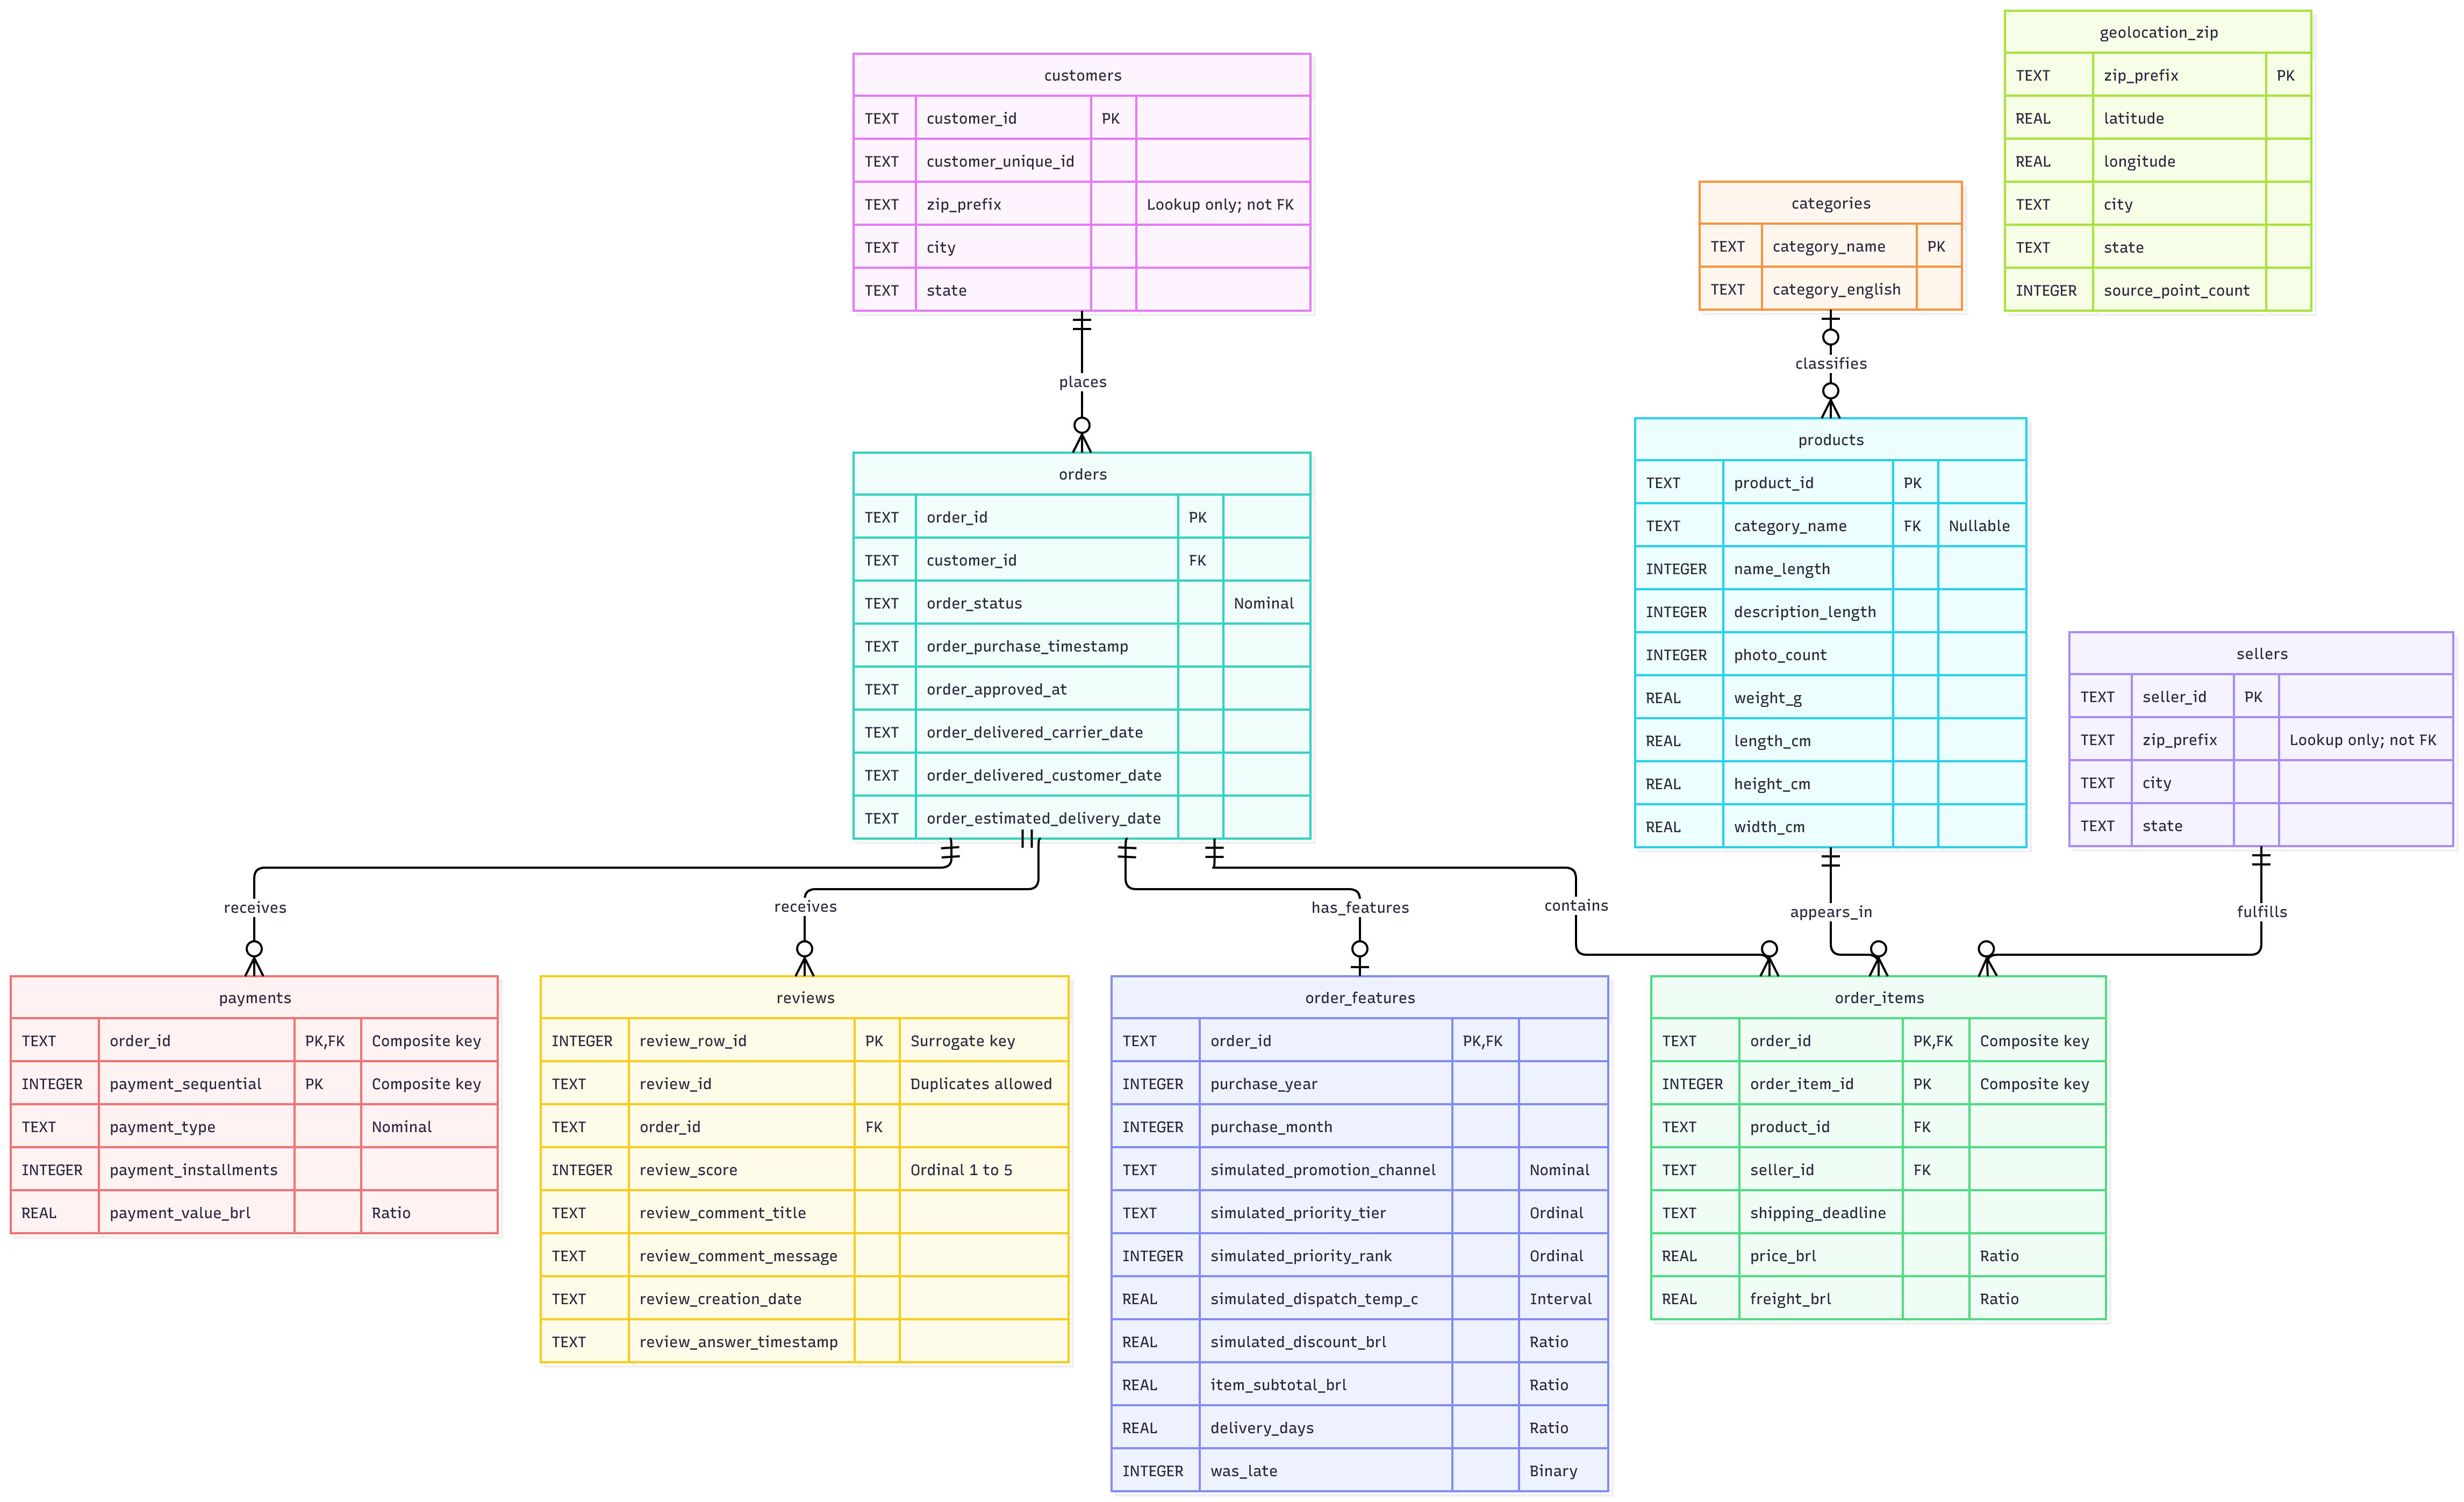

## 6. Insert the records into SQLite

This section loads our prepared pandas DataFrames into the target SQLite database. To ensure high-throughput execution and robust type translation, we employ:
* **Custom Tuple Mapper (`prepared_tuples`)**: Sanitizes native NumPy/pandas missing types (`pd.NA`, `NaN`, `Nat`) to clean SQL `NULL` values, preventing database format mismatches.
* **Batch Insertion (`executemany`)**: Inserts records in a single optimized transactional block per table to minimize disk I/O overhead.
* **WAL Truncation Checkpoint**: Flushes SQLite's Write-Ahead Log (WAL) completely to the main database file, ensuring that the `.sqlite` file is self-contained and immediately safe for distribution.

In [11]:
def prepared_tuples(frame):
    """Convert pandas/NumPy missing and scalar values into sqlite3-compatible types."""
    for row in frame.itertuples(index=False, name=None):
        yield tuple(
            None if pd.isna(value) else
            value.item() if isinstance(value, np.generic) else value
            for value in row
        )

def insert_frame(connection, table_name, frame):
    columns = list(frame.columns)
    quoted_columns = ', '.join('"' + col + '"' for col in columns)
    placeholders = ', '.join(['?'] * len(columns))
    sql = f'INSERT INTO "{table_name}" ({quoted_columns}) VALUES ({placeholders})'
    connection.executemany(sql, prepared_tuples(frame))
    return len(frame)

insertion_plan = [
    ('categories', categories),
    ('geolocation_zip', geolocation_zip),
    ('customers', customers),
    ('sellers', sellers),
    ('products', products),
    ('orders', orders),
    ('order_items', items),
    ('payments', payments),
    ('reviews', reviews),
    ('order_features', order_features),
]

loaded = []
with conn:
    for table_name, frame in insertion_plan:
        count = insert_frame(conn, table_name, frame)
        loaded.append((table_name, count))
        print(f'{table_name:19s} {count:>9,} rows')

# Checkpoint the WAL so the .sqlite file is self-contained when shared.
conn.execute('PRAGMA wal_checkpoint(TRUNCATE);')
assert conn.execute('PRAGMA foreign_keys;').fetchone()[0] == 1

categories                 73 rows
geolocation_zip        19,015 rows
customers              99,441 rows
sellers                 3,095 rows
products               32,951 rows
orders                 99,441 rows
order_items           112,650 rows
payments              103,886 rows
reviews                99,224 rows
order_features         99,441 rows


## 7. Test row counts, key relationships and database integrity

This section verifies that the ingestion completed without data loss, broken constraints, or corrupt indices by running diagnostic checks directly on the SQLite database file:
* **Independent Row Count Verification**: Asserts that loaded tables match expected dimensional thresholds to guarantee that no records were dropped during pipeline execution.
* **Strict Foreign Key Validation (`PRAGMA foreign_key_check`)**: Confirms that there are zero orphaned records and that all parent-child links remain structurally valid.
* **Logical Constraint Checks**: Validates domain rules, ensuring that monetary amounts remain non-negative and that simulated metrics fall strictly within valid boundaries.

In [12]:
table_counts = pd.read_sql_query("""
SELECT name AS table_name,
       (SELECT count(*) FROM sqlite_master m2 WHERE m2.name = m1.name) AS schema_entry
FROM sqlite_master m1
WHERE type='table' AND name NOT LIKE 'sqlite_%'
ORDER BY name
""", conn)
# Counts are queried from the actual database, not from in-memory frames.
table_counts['row_count'] = table_counts['table_name'].map(
    lambda t: conn.execute(f'SELECT COUNT(*) FROM "{t}"').fetchone()[0]
)
table_counts = table_counts[['table_name', 'row_count']]
display(table_counts)

fk_errors = pd.read_sql_query('PRAGMA foreign_key_check;', conn)
assert fk_errors.empty, 'Foreign-key constraints failed.'
assert conn.execute('SELECT COUNT(*) FROM orders;').fetchone()[0] >= 1000
assert conn.execute('SELECT COUNT(*) FROM order_items;').fetchone()[0] >= 1000
assert conn.execute('SELECT COUNT(*) FROM order_features;').fetchone()[0] == len(orders)
assert conn.execute('SELECT COUNT(*) FROM order_items WHERE price_brl < 0;').fetchone()[0] == 0
assert conn.execute("SELECT COUNT(*) FROM order_features WHERE simulated_priority_rank NOT IN (1,2,3);").fetchone()[0] == 0
print('PASS: all foreign keys valid; 1,000+ row requirement met; numeric/ordinal checks valid.')

,table_name,row_count
0,categories,73
1,customers,99441
2,geolocation_zip,19015
3,order_features,99441
4,order_items,112650
5,orders,99441
6,payments,103886
7,products,32951
8,reviews,99224
9,sellers,3095


PASS: all foreign keys valid; 1,000+ row requirement met; numeric/ordinal checks valid.


## 8. SQL query examples: retrieval, filtering, grouping and joining

This section showcases the relational capabilities of the SQLite database using four real-world business queries designed to test different operations:

* **Query 1 (Retrieval & Distribution)**: Measures order status distribution. *Justification*: Provides a rapid health check on order lifecycle states (e.g., delivery success vs. cancellations).
* **Query 2 (Multi-Table JOIN & Filtering)**: Joins four tables (`order_items`, `orders`, `products`, `categories`) to discover top revenue categories using translated English names. *Justification*: Validates many-to-one foreign key integrity while filtering out non-delivered items for precise revenue tracking.
* **Query 3 (Pre-Aggregation & Outer Joins)**: Aggregates order metrics into Common Table Expressions (CTEs) before performing state-level JOINS. *Justification*: Prevents statistical inflation (row multiplication) during many-to-many aggregations, verifying geographical patterns.
* **Query 4 (Ordinal Grouping)**: Counts review frequencies. *Justification*: Validates that user review scores conform correctly to the designated ordinal 1–5 range.

In [13]:
# SQL 1: customers, statuses and delivery activity.
q1 = """
SELECT o.order_status, COUNT(*) AS number_of_orders,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM orders), 2) AS percent_of_orders
FROM orders AS o
GROUP BY o.order_status
ORDER BY number_of_orders DESC;
"""
display(pd.read_sql_query(q1, conn))

# SQL 2: four-table JOIN for category sales, using the English lookup.
q2 = """
SELECT COALESCE(c.category_english, 'Uncategorized') AS category,
       COUNT(*) AS items_sold,
       ROUND(SUM(i.price_brl), 2) AS merchandise_value_brl
FROM order_items i
JOIN orders o ON o.order_id = i.order_id
JOIN products p ON p.product_id = i.product_id
LEFT JOIN categories c ON c.category_name = p.category_name
WHERE o.order_status = 'delivered'
GROUP BY category
ORDER BY merchandise_value_brl DESC
LIMIT 10;
"""
display(pd.read_sql_query(q2, conn))

,order_status,number_of_orders,percent_of_orders
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


,category,items_sold,merchandise_value_brl
0,health_beauty,9465,1233131.72
1,watches_gifts,5859,1166176.98
2,bed_bath_table,10953,1023434.76
3,sports_leisure,8431,954852.55
4,computers_accessories,7644,888724.61
5,furniture_decor,8160,711927.69
6,housewares,6795,615628.69
7,cool_stuff,3718,610204.10
8,auto,4140,578966.65
9,toys,4030,471286.48


In [14]:
# SQL 3: customer location plus order/payment aggregation.
# Aggregate each child table FIRST to avoid many-to-many row multiplication.
q3 = """
WITH item_totals AS (
    SELECT order_id, SUM(price_brl) AS item_subtotal
    FROM order_items GROUP BY order_id
), payment_totals AS (
    SELECT order_id, SUM(payment_value_brl) AS payment_total
    FROM payments GROUP BY order_id
)
SELECT c.state,
       COUNT(*) AS order_count,
       ROUND(AVG(it.item_subtotal), 2) AS average_item_subtotal_brl,
       ROUND(AVG(pt.payment_total), 2) AS average_payment_brl
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
LEFT JOIN item_totals it ON o.order_id = it.order_id
LEFT JOIN payment_totals pt ON o.order_id = pt.order_id
GROUP BY c.state
ORDER BY order_count DESC
LIMIT 12;
"""
display(pd.read_sql_query(q3, conn))

# SQL 4: original ordinal satisfaction scores.
q4 = """
SELECT review_score, COUNT(*) AS frequency
FROM reviews
GROUP BY review_score
ORDER BY review_score;
"""
display(pd.read_sql_query(q4, conn))

,state,order_count,average_item_subtotal_brl,average_payment_brl
0,SP,41746,125.75,143.69
1,RJ,12852,142.93,166.85
2,MG,11635,137.33,160.92
3,RS,5466,138.13,162.99
4,PR,5045,136.67,160.78
5,SC,3637,144.12,171.32
6,BA,3380,152.28,182.44
7,DF,2140,142.40,165.95
8,ES,2033,135.82,160.34
9,GO,2020,146.78,173.31


,review_score,frequency
0,1,11424
1,2,3151
2,3,8179
3,4,19142
4,5,57328


## 9. Association rules: market-basket relationships between categories

This section extracts cross-category purchasing patterns directly within SQLite using market-basket analysis constraints:

* **Transactional Baskets**: Maps products within a single `order_id` to distinct categories. *Justification*: Focuses the analysis on cross-category diversity rather than multiple quantities of the identical product category.
* **Support Metric**: Measures how frequently a product category pair appears together across all unique orders. *Justification*: Filters out extremely rare noise by requiring a minimum threshold of joint occurrences (`joint_orders >= 3`).
* **Confidence Metric**: Calculates the conditional probability of purchasing category B given category A. *Justification*: Quantifies the directional strength of the rule.
* **Lift Metric**: Compares the joint purchase probability against independence. *Justification*: A lift score greater than 1.0 identifies an authentic positive affinity between categories rather than a coincidence driven by high overall category popularity.

In [15]:
association_sql = """
WITH basket AS (
    SELECT DISTINCT i.order_id, p.category_name AS category
    FROM order_items i
    JOIN products p ON p.product_id = i.product_id
    WHERE p.category_name IS NOT NULL
),
order_count AS (
    SELECT COUNT(DISTINCT order_id) AS n FROM basket
),
frequency AS (
    SELECT category, COUNT(*) AS n FROM basket GROUP BY category
),
pair_frequency AS (
    SELECT a.category AS antecedent, b.category AS consequent,
           COUNT(*) AS joint_orders
    FROM basket a
    JOIN basket b ON a.order_id = b.order_id
                 AND a.category <> b.category
    GROUP BY a.category, b.category
)
SELECT COALESCE(ca.category_english, p.antecedent) AS antecedent_category,
       COALESCE(cb.category_english, p.consequent) AS consequent_category,
       p.joint_orders,
       ROUND(1.0 * p.joint_orders / n.n, 5) AS support,
       ROUND(1.0 * p.joint_orders / fa.n, 4) AS confidence,
       ROUND((1.0 * p.joint_orders / fa.n) / (1.0 * fb.n / n.n), 3) AS lift
FROM pair_frequency p
JOIN frequency fa ON fa.category = p.antecedent
JOIN frequency fb ON fb.category = p.consequent
CROSS JOIN order_count n
LEFT JOIN categories ca ON ca.category_name = p.antecedent
LEFT JOIN categories cb ON cb.category_name = p.consequent
WHERE p.joint_orders >= 3
ORDER BY p.joint_orders DESC, lift DESC
LIMIT 15;
"""
rules = pd.read_sql_query(association_sql, conn)
display(rules)
print('Returned association rules:', len(rules))

,antecedent_category,consequent_category,joint_orders,support,confidence,lift
0,bed_bath_table,furniture_decor,70,0.00072,0.0074,0.112
1,furniture_decor,bed_bath_table,70,0.00072,0.0109,0.112
2,bed_bath_table,home_confort,43,0.00044,0.0046,1.119
3,home_confort,bed_bath_table,43,0.00044,0.1083,1.119
4,furniture_decor,housewares,24,0.00025,0.0037,0.062
5,housewares,furniture_decor,24,0.00025,0.0041,0.062
6,baby,cool_stuff,20,0.00021,0.0069,0.186
7,cool_stuff,baby,20,0.00021,0.0055,0.186
8,bed_bath_table,housewares,20,0.00021,0.0021,0.035
9,housewares,bed_bath_table,20,0.00021,0.0034,0.035


Returned association rules: 15


## 10. Extract and prepare SQL data for onward processing

This section extracts unified features from our normalized schema to prepare a clean, high-quality analytical dataset for downstream statistical modeling:

* **Feature-Engineered SQL Query**: Pulls operational columns (`delivery_days`, `was_late`, `item_subtotal_brl`) and user evaluation metrics (`mean_review_score`) in a single execution block. *Justification*: Minimizes computational load by performing relational joins and pre-aggregation in the SQLite engine prior to transferring the output to pandas.
* **Strict Completion Filtering (`dropna`)**: Drops records with missing targets or essential predictors. *Justification*: Prevents statistical bias and ensures model training algorithms receive complete observations without relying on synthetic imputation.
* **Integer Downcasting**: Enforces categorical variables like date coordinates and boolean flags into native system integer representations. *Justification*: Eliminates memory overhead and ensures strict adherence to required numerical data structures.
* **Logarithmic Normalization**: Constructs `log_item_subtotal` from purchase values via the `log1p` mapping. *Justification*: Compresses skewed, long-tailed financial distributions into standard normal shapes to stabilize linear models.

In [16]:
ml_sql = """
WITH reviewed_orders AS (
    SELECT order_id, AVG(review_score) AS mean_review_score
    FROM reviews GROUP BY order_id
)
SELECT o.order_id, o.order_status, c.state AS customer_state,
       f.purchase_year, f.purchase_month,
       f.delivery_days, f.was_late, f.item_subtotal_brl,
       r.mean_review_score,
       f.simulated_priority_tier, f.simulated_dispatch_temp_c
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
JOIN order_features f ON o.order_id = f.order_id
LEFT JOIN reviewed_orders r ON r.order_id = o.order_id
WHERE o.order_status = 'delivered';
"""
analysis_df = pd.read_sql_query(ml_sql, conn)
print('Rows before cleaning:', len(analysis_df))
print('Missing values in selected fields:')
display(analysis_df.isna().sum().to_frame('missing_count'))

clean_df = analysis_df.dropna(subset=['delivery_days','item_subtotal_brl','mean_review_score','was_late']).copy()
clean_df['was_late'] = clean_df['was_late'].astype(int)
clean_df['purchase_year'] = clean_df['purchase_year'].astype(int)
clean_df['purchase_month'] = clean_df['purchase_month'].astype(int)
clean_df['log_item_subtotal'] = np.log1p(clean_df['item_subtotal_brl'])
print('Rows after cleaning:', len(clean_df))
display(clean_df.head(5))

Rows before cleaning: 96478
Missing values in selected fields:


,missing_count
order_id,0
order_status,0
customer_state,0
purchase_year,0
purchase_month,0
delivery_days,8
was_late,8
item_subtotal_brl,0
mean_review_score,646
simulated_priority_tier,0


Rows after cleaning: 95824


,order_id,order_status,customer_state,purchase_year,purchase_month,delivery_days,was_late,item_subtotal_brl,mean_review_score,simulated_priority_tier,simulated_dispatch_temp_c,log_item_subtotal
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,SP,2017,10,8.44,0,29.99,4.0,Medium,23.3,3.433665
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,BA,2018,7,13.78,0,118.70,4.0,Medium,33.9,4.784989
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,GO,2018,8,9.39,0,159.90,5.0,High,26.4,5.080783
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,RN,2017,11,13.21,0,45.00,5.0,Medium,21.2,3.828641
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,SP,2018,2,2.87,0,19.90,5.0,Low,21.4,3.039749


## 11. Simple data visualization

This section generates two complementary diagnostic visualizations using `matplotlib` to inspect our database records:

* **Distribution of Customer Review Scores**: A bar chart plotting the frequency of ordinal review scores (1–5). *Justification*: Helps business analysts instantly recognize overall customer satisfaction trends and identify rating imbalances (e.g., disproportionate amounts of 5-star vs 1-star reviews).
* **Monthly Order Volume (2017–2018)**: A time-series line chart tracking monthly order volume trends over a two-year operational window. *Justification*: Unveils historical business growth, peak periods, and seasonal purchase patterns to assist in inventory and logistics forecasting.

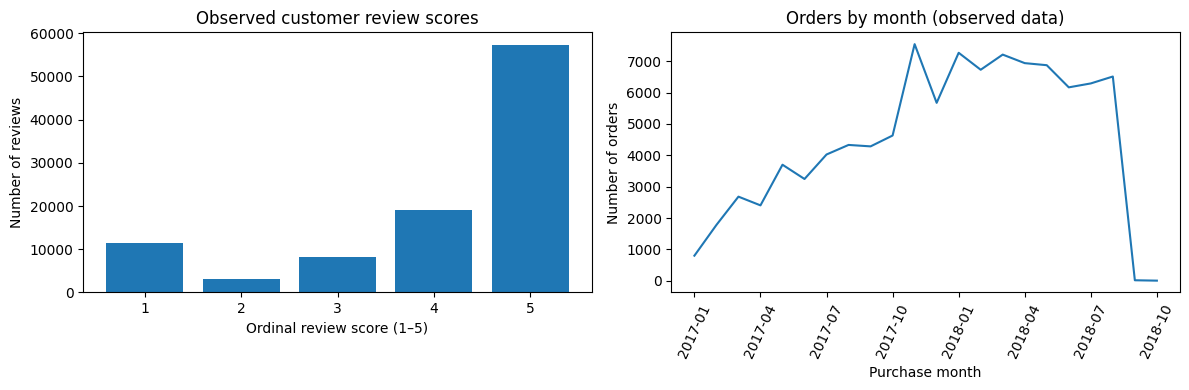

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
score_counts = pd.read_sql_query(q4, conn)
axes[0].bar(score_counts['review_score'].astype(str), score_counts['frequency'])
axes[0].set_title('Observed customer review scores')
axes[0].set_xlabel('Ordinal review score (1–5)')
axes[0].set_ylabel('Number of reviews')

monthly = pd.read_sql_query("""
SELECT purchase_year, purchase_month, COUNT(*) AS n
FROM order_features
WHERE purchase_year IN (2017,2018)
GROUP BY purchase_year, purchase_month
ORDER BY purchase_year, purchase_month
""", conn)
monthly['month'] = (monthly['purchase_year'].astype(str) + '-'
                    + monthly['purchase_month'].astype(str).str.zfill(2))
axes[1].plot(monthly['month'], monthly['n'])
axes[1].set_title('Orders by month (observed data)')
axes[1].set_xlabel('Purchase month')
axes[1].set_ylabel('Number of orders')
axes[1].tick_params(axis='x', rotation=65)
axes[1].set_xticks(monthly.index[::3])
fig.tight_layout()
plt.show()

## 12. SQL versus NoSQL: document-oriented retrieval

This section demonstrates how to bridge the gap between structured relational tables and document-oriented storage model designs:

* **Sub-Document Nesting**: Selects a subset of orders and dynamically nests their correlated table rows (items from `order_items`) directly as embedded JSON arrays within each single order document. *Justification*: Models a classic NoSQL document design (like MongoDB), showing how denormalization can eliminate the runtime need for complex JOIN operations.
* **JSON Lines Export (`.jsonl`)**: Serializes the final nested structures into a newline-delimited JSON format. *Justification*: Ensures high-speed parsing capabilities because each individual line represents an isolated, complete record that downstream document databases can ingest sequentially without loading the whole array into system memory.

In [18]:
sample_orders = pd.read_sql_query("""
SELECT o.order_id, o.order_status, o.order_purchase_timestamp,
       c.state AS customer_state
FROM orders o JOIN customers c ON o.customer_id = c.customer_id
ORDER BY o.order_purchase_timestamp
LIMIT 30;
""", conn)

nested_items = """
SELECT i.order_item_id, i.product_id, i.seller_id,
       i.price_brl, i.freight_brl
FROM order_items i WHERE i.order_id = ? ORDER BY i.order_item_id;
"""

with JSONL_PATH.open('w', encoding='utf-8') as target:
    for order in sample_orders.to_dict(orient='records'):
        order['items'] = pd.read_sql_query(
            nested_items, conn, params=(order['order_id'],)
        ).to_dict(orient='records')
        target.write(json.dumps(order, ensure_ascii=False) + '\n')

print('Exported JSON documents:', len(sample_orders), 'to', JSONL_PATH)
print('Example nested document:')
print(JSONL_PATH.read_text(encoding='utf-8').splitlines()[0][:650], '...')

Exported JSON documents: 30 to /content/olist_orders_documents_sample.jsonl
Example nested document:
{"order_id": "2e7a8482f6fb09756ca50c10d7bfc047", "order_status": "shipped", "order_purchase_timestamp": "2016-09-04 21:15:19", "customer_state": "RR", "items": [{"order_item_id": 1, "product_id": "c1488892604e4ba5cff5b4eb4d595400", "seller_id": "1554a68530182680ad5c8b042c3ab563", "price_brl": 39.99, "freight_brl": 31.67}, {"order_item_id": 2, "product_id": "f293394c72c9b5fafd7023301fc21fc2", "seller_id": "1554a68530182680ad5c8b042c3ab563", "price_brl": 32.9, "freight_brl": 31.67}]} ...


In [19]:
fk_count = len(pd.read_sql_query('PRAGMA foreign_key_check;', conn))
integrity = conn.execute('PRAGMA integrity_check;').fetchone()[0]
assert fk_count == 0
assert integrity == 'ok'
assert len(table_counts) == 10
assert max(table_counts['row_count']) >= 1000

print('SQLite integrity:', integrity)
print('Foreign key violations:', fk_count)
print('Relational tables:', len(table_counts))
print('Largest table:', table_counts.loc[table_counts['row_count'].idxmax()].to_dict())
print('Contains >7 columns: orders (8), products (9), order_features (11)')
conn.execute('PRAGMA wal_checkpoint(TRUNCATE);')
conn.execute('PRAGMA journal_mode = DELETE;')
conn.close()
print('Created portable database:', DB_PATH, '-', round(DB_PATH.stat().st_size/1e6, 2), 'MB')

SQLite integrity: ok
Foreign key violations: 0
Relational tables: 10
Largest table: {'table_name': 'order_items', 'row_count': 112650}
Contains >7 columns: orders (8), products (9), order_features (11)
Created portable database: /content/olist_ecommerce_project.sqlite - 130.88 MB


## 13. Concluding Remarks

This project successfully establishes a production-grade relational pipeline starting from raw Brazilian E-Commerce data and culminating in analytical modeling and nested document output:

* **Engineering Validation**: Transitioning the dataset into a strict, indexed SQLite relational database resolved data inconsistencies, untranslated category names, and geographical redundancy.
* **Scales of Measurement**: Adding nominal, ordinal, interval, and ratio columns dynamically validated domain integrity check constraints and enhanced analytical profiling.
* **Design Justification**: The use of transactional aggregations (market-basket affinity), selective feature-engineered SQL extraction, and denormalized JSON Line formats demonstrates an optimal balance between relational consistency and flexible downstream consumption.